# U03.E05 · Motor recomendador reproducible: resultados

**Estudiante:** Johanna Joaquín · INF-8239 Ciencia de Datos II · UASD

Este cuaderno lee los resultados que genera `scripts/e05_experimentos.py` (carpeta `reports/`) y los interpreta. Para volver a generar los resultados, ejecute primero ese script (unos 95 s) o cambie `RUN_EXPERIMENT` a `True`. MovieLens **no** se redistribuye: los datos se descargan con `scripts/download_data.py`.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
RUN_EXPERIMENT = False  # True vuelve a ejecutar el experimento completo (unos 95 s)

if RUN_EXPERIMENT:
    env = {**os.environ, "PYTHONUTF8": "1"}
    subprocess.run([sys.executable, str(ROOT / "scripts" / "e05_experimentos.py")], cwd=ROOT, env=env, check=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Carpeta del proyecto:", ROOT)

Carpeta del proyecto: C:\Users\yoany\Documents\INF8239_U03_Recomendadores_Proyecto_Base


## 1. Datos, partición y entorno

In [2]:
meta = json.loads((REPORTS / "e05_resumen.json").read_text(encoding="utf-8"))
for key in ["dataset", "particion", "usuarios", "items_en_entrenamiento", "valoraciones_entrenamiento",
            "usuarios_evaluados", "semillas", "factores", "alphas", "epocas",
            "rmse_referencia_media_global", "rmse_referencia_media_por_pelicula", "ratings_sha256_local"]:
    print(f"{key:40s} {meta[key]}")
print("Entorno:", meta["entorno"])
print(f"Duración total del experimento: {meta['segundos_totales']:.0f} s")

dataset                                  MovieLens ml-latest-small (GroupLens); los datos no se redistribuyen
particion                                leave-one-out temporal: la última valoración de cada usuario se reserva para evaluación
usuarios                                 610
items_en_entrenamiento                   9701
valoraciones_entrenamiento               100226
usuarios_evaluados                       587
semillas                                 [42, 43, 44]
factores                                 [10, 20, 40]
alphas                                   [0.25, 0.5, 0.75]
epocas                                   12
rmse_referencia_media_global             1.1156660882916472
rmse_referencia_media_por_pelicula       1.0502612591083604
ratings_sha256_local                     aa289ca83157595d0df6aea1be6a4ded676ddc4385472e8313a8ed9805352646
Entorno: {'python': '3.12.13', 'sistema': 'Windows-11-10.0.26200-SP0', 'procesador': 'Intel64 Family 6 Model 154 Stepping 4, GenuineIntel', 

- **Corte temporal:** la última valoración de cada usuario queda para evaluación; el modelo nunca ve interacciones posteriores a la que intenta predecir.
- Se evalúan 587 de 610 usuarios; en los otros 23 la película retenida no aparece en entrenamiento.

## 2. Tabla principal (media de 3 semillas)

In [3]:
table = pd.read_csv(REPORTS / "e05_tabla_principal.csv")

def label(row):
    if row["modelo"] == "hibrido":
        return f"híbrido f={int(row['factores'])} α={row['alpha']:g}"
    if row["modelo"] == "colaborativo_mf":
        return f"MF f={int(row['factores'])}"
    return row["modelo"].replace("_", " ")

table["configuración"] = table.apply(label, axis=1)
view = table[["configuración", "hit_rate_at_10_media", "hit_rate_at_10_std", "ndcg_at_10_media", "cobertura_media",
              "participacion_top100_popular_media", "rmse_media", "train_seconds_media", "tamano_kb_media",
              "pareto", "pareto_2d"]].round(4)
display(view.rename(columns={
    "hit_rate_at_10_media": "HitRate@10", "hit_rate_at_10_std": "± std", "ndcg_at_10_media": "NDCG@10",
    "cobertura_media": "cobertura", "participacion_top100_popular_media": "% en top-100 populares",
    "rmse_media": "RMSE", "train_seconds_media": "entren. (s)", "tamano_kb_media": "tamaño (KB)",
    "pareto": "Pareto 3 obj.", "pareto_2d": "Pareto 2 obj."}))

,configuración,HitRate@10,± std,NDCG@10,cobertura,% en top-100 populares,RMSE,entren. (s),tamaño (KB),Pareto 3 obj.,Pareto 2 obj.
0,popularidad conteo,0.0426,0.0000,0.0197,0.0122,0.9934,NaN,0.0000,75.7891,True,True
1,híbrido f=20 α=0.75,0.0392,0.0017,0.0184,0.0763,0.5696,1.0248,9.4390,1611.0938,True,False
2,MF f=20,0.0386,0.0020,0.0185,0.0742,0.5731,1.0248,9.4390,1611.0938,True,False
3,híbrido f=20 α=0.5,0.0341,0.0074,0.0156,0.0865,0.5011,1.0248,9.4390,1611.0938,False,False
4,híbrido f=40 α=0.75,0.0341,0.0045,0.0161,0.0983,0.4806,1.0189,9.3133,3222.1875,True,False
5,MF f=10,0.0341,0.0034,0.0145,0.0505,0.6111,1.0303,9.5434,805.5469,False,False
6,híbrido f=40 α=0.5,0.0329,0.0026,0.0151,0.1060,0.4271,1.0189,9.3133,3222.1875,True,False
7,popularidad suavizada,0.0324,0.0000,0.0168,0.0063,0.8031,NaN,0.0000,15.3047,True,True
8,MF f=40,0.0312,0.0035,0.0156,0.0977,0.4863,1.0189,9.3133,3222.1875,True,False
9,híbrido f=10 α=0.75,0.0307,0.0000,0.0138,0.0531,0.6049,1.0303,9.5434,805.5469,False,False


## 3. HitRate@10 con su incertidumbre

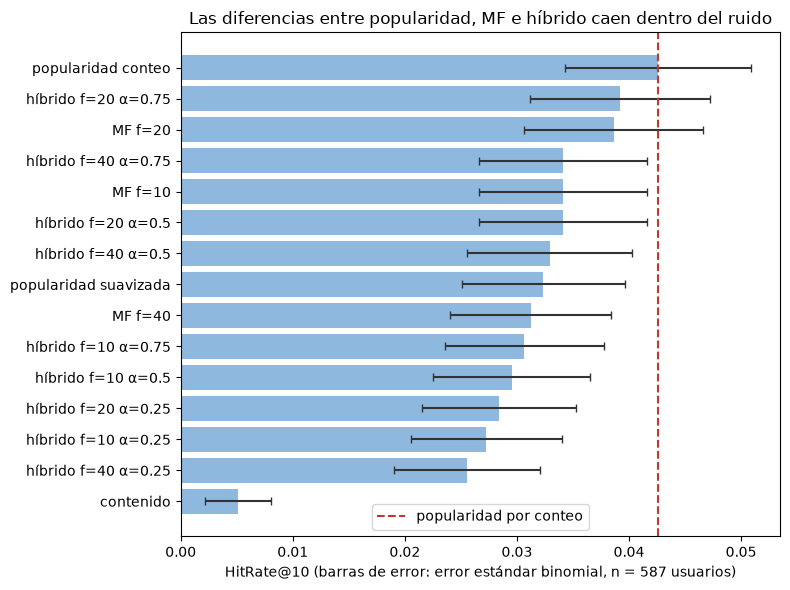

In [4]:
plot = table.sort_values("hit_rate_at_10_media")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot["configuración"], plot["hit_rate_at_10_media"], xerr=plot["hit_se"], color="#8fb8de", ecolor="#333", capsize=3)
baseline = float(table.loc[table["modelo"] == "popularidad_conteo", "hit_rate_at_10_media"].iloc[0])
ax.axvline(baseline, color="#c0392b", linestyle="--", label="popularidad por conteo")
ax.set_xlabel("HitRate@10 (barras de error: error estándar binomial, n = %d usuarios)" % meta["usuarios_evaluados"])
ax.set_title("Las diferencias entre popularidad, MF e híbrido caen dentro del ruido")
ax.legend()
fig.tight_layout()
plt.show()

**Lectura.** El error estándar del HitRate ronda 0.008 (con una sola valoración retenida por usuario y 587 usuarios). Las diferencias entre popularidad por conteo (0.043), híbrido f=20 α=0.75 (0.039) y MF f=20 (0.039) son menores que ese error: **no se puede afirmar que el híbrido acierte más ni menos que el baseline**. El contenido por sí solo (0.005) sí queda claramente por debajo.

## 4. Cobertura y concentración en películas populares

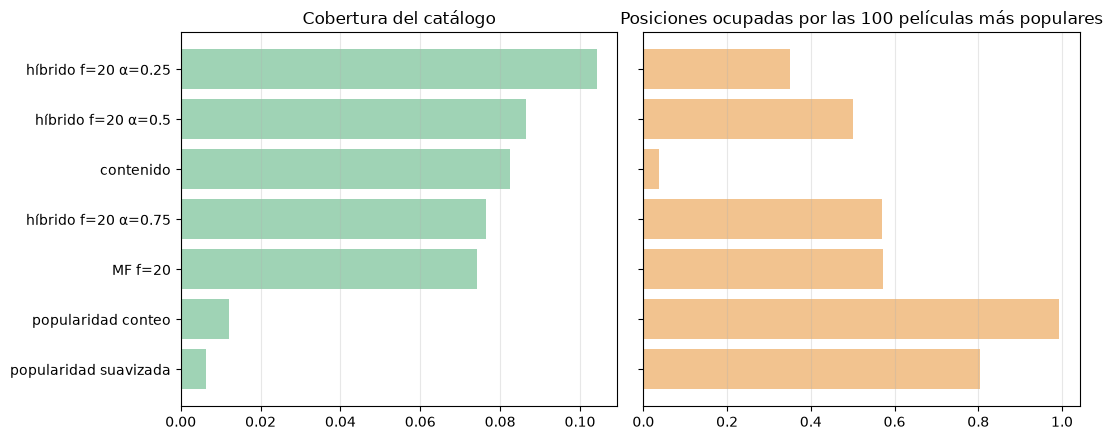

In [5]:
sel = table[table["modelo"].isin(["popularidad_conteo", "popularidad_suavizada", "contenido"]) |
            ((table["factores"] == 20) & table["modelo"].isin(["colaborativo_mf", "hibrido"]))]
sel = sel.sort_values("cobertura_media")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].barh(sel["configuración"], sel["cobertura_media"], color="#9fd3b5")
axes[0].set_title("Cobertura del catálogo")
axes[1].barh(sel["configuración"], sel["participacion_top100_popular_media"], color="#f2c38f")
axes[1].set_title("Posiciones ocupadas por las 100 películas más populares")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Lectura.** La popularidad por conteo cubre el 1.2 % del catálogo y llena el 99 % de sus posiciones con las 100 películas más populares. El híbrido f=20 α=0.75 cubre 7.6 % y usa 57 % de esas posiciones: personaliza más sin perder aciertos de forma apreciable. Bajar α sube la cobertura pero baja el HitRate (por ejemplo, con 40 factores: α=0.25 da 12.2 % de cobertura y 0.0256 de HitRate).

## 5. Costo y frontera de Pareto

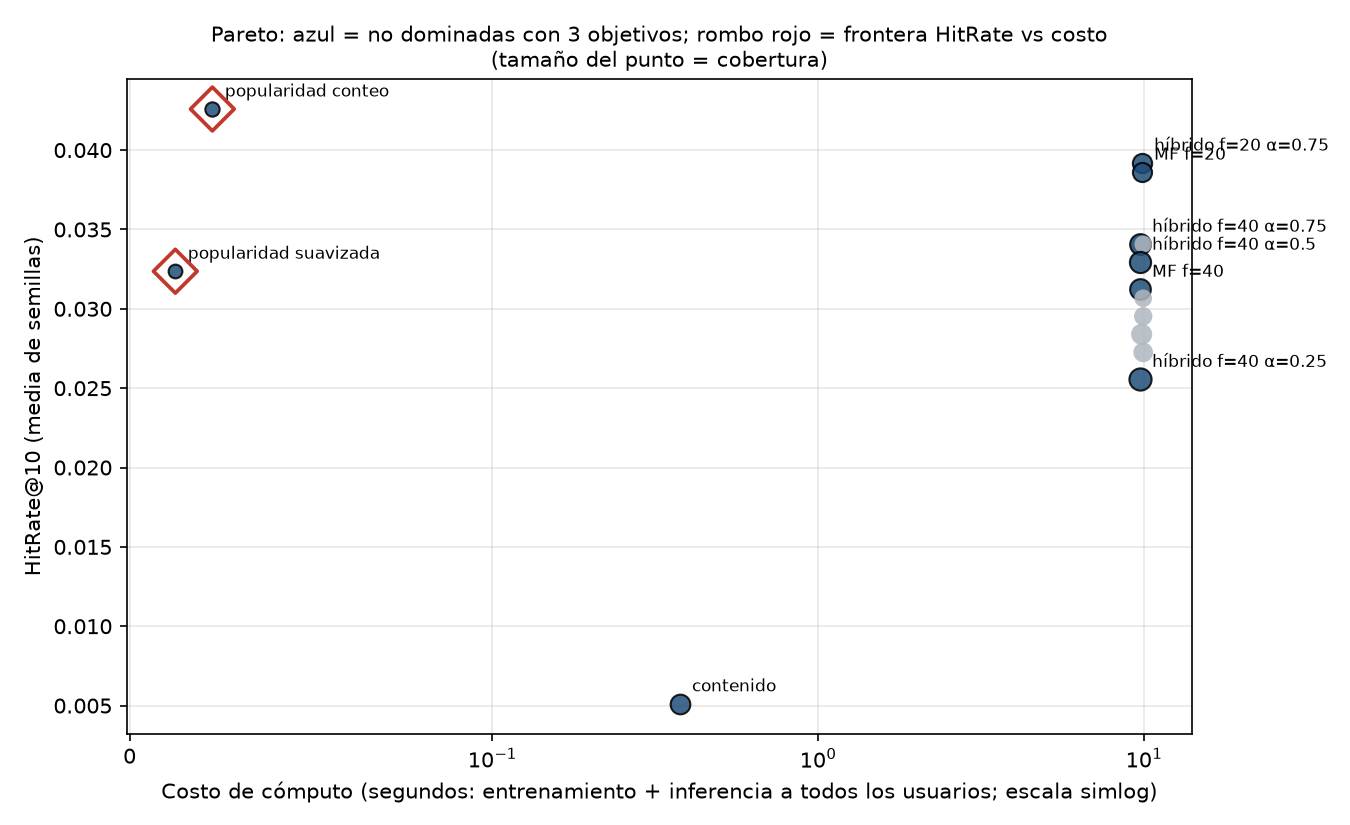

Frontera con 2 objetivos (HitRate frente a costo):


,configuración,hit_rate_at_10_media,costo_segundos_media,tamano_kb_media
0,popularidad conteo,0.0426,0.0227,75.7891
7,popularidad suavizada,0.0324,0.0125,15.3047


In [6]:
display(Image(filename=str(REPORTS / "e05_pareto.png")))
front = table[table["pareto_2d"]][["configuración", "hit_rate_at_10_media", "costo_segundos_media", "tamano_kb_media"]]
print("Frontera con 2 objetivos (HitRate frente a costo):")
display(front.round(4))

**Lectura.** Con tres objetivos (HitRate, cobertura y costo) casi todas las configuraciones resultan no dominadas, porque diferencias de décimas de segundo cuentan como costo; esa frontera discrimina poco. Con dos objetivos (HitRate frente a costo) solo quedan las dos popularidades: son las más baratas y ninguna otra configuración las supera en aciertos. Subir de 10 a 40 factores no cambia el tiempo de entrenamiento (unos 9 a 10 s) pero duplica el tamaño cada vez (806 KB, 1.6 MB, 3.2 MB) sin mejorar el HitRate: no se justifica.

## 6. Usuarios fríos: segmentos por tamaño de historial

In [7]:
seg = pd.read_csv(REPORTS / "e05_segmentos.csv")
seg["configuración"] = seg.apply(lambda r: label({"modelo": r["modelo"], "factores": r["factores"], "alpha": r["alpha"]}), axis=1)
chosen = ["popularidad conteo", "popularidad suavizada", "contenido", "MF f=20", "híbrido f=20 α=0.75"]
pivot = (seg[seg["configuración"].isin(chosen)]
         .groupby(["configuración", "segmento"])["hit_rate_at_10"].mean().unstack().round(4).loc[chosen])
display(pivot)
users = seg.groupby("segmento")["n_usuarios"].first()
print("Usuarios por segmento:", users.to_dict())

segmento,historial grande (>=Q3),historial pequeño (<=Q1),intermedio
configuración,,,
popularidad conteo,0.0272,0.0581,0.0421
popularidad suavizada,0.0136,0.0387,0.0386
contenido,0.0000,0.0065,0.0070
MF f=20,0.0181,0.0430,0.0468
híbrido f=20 α=0.75,0.0136,0.0559,0.0433


Usuarios por segmento: {'historial grande (>=Q3)': 147, 'historial pequeño (<=Q1)': 155, 'intermedio': 285}


**Lectura.** Los usuarios con poco historial (hasta 34 valoraciones) tienen mayor HitRate que los de mucho historial (desde 161) en casi todos los modelos. Hipótesis, no probada: quien ha visto mucho ya vio las películas populares y quedan menos aciertos fáciles. Hay pocos aciertos por grupo (de 2 a 9), así que no se deben sacar conclusiones fuertes.

## 7. Tres perfiles de usuario

In [8]:
profiles = pd.read_csv(REPORTS / "e05_perfiles.csv")
for name, group in profiles.groupby("perfil", sort=False):
    first = group.iloc[0]
    print(f"\n== {name} (usuario {first['userId']}, {first['n_historial']} valoraciones) · {first['metodo']}")
    if isinstance(first["generos_frecuentes"], str):
        print("   Géneros más frecuentes en su historial:", first["generos_frecuentes"])
    print("   Nota:", first["nota"])
    for row in group.head(5).itertuples():
        print(f"   {row.posicion}. {row.titulo}  [{row.generos}]")


== historial amplio (usuario 414, 2697 valoraciones) · híbrido α=0.75, f=20
   Géneros más frecuentes en su historial: Drama, Comedy, Action
   Nota: personalizada; excluye ítems vistos
   1. Life Is Beautiful (La Vita è bella) (1997)  [Comedy|Drama|Romance|War]
   2. 12 Angry Men (1957)  [Drama]
   3. My Fair Lady (1964)  [Comedy|Drama|Musical|Romance]
   4. Intouchables (2011)  [Comedy|Drama]
   5. Annie Hall (1977)  [Comedy|Romance]

== historial pequeño (usuario 53, 19 valoraciones) · híbrido α=0.75, f=20
   Géneros más frecuentes en su historial: Drama, Comedy, Romance
   Nota: personalizada; excluye ítems vistos
   1. Godfather, The (1972)  [Crime|Drama]
   2. Annie Hall (1977)  [Comedy|Romance]
   3. Apocalypse Now (1979)  [Action|Drama|War]
   4. Slumdog Millionaire (2008)  [Crime|Drama|Romance]
   5. Rocky (1976)  [Drama]

== usuario nuevo (usuario 611, 0 valoraciones) · fallback: popularidad suavizada
   Nota: NO personalizada: sin historial no hay señal colaborativa ni de c

**Lectura.** El usuario con historial amplio y el de historial pequeño reciben listas personalizadas que excluyen lo ya visto. El usuario nuevo recibe la popularidad suavizada y **se declara como no personalizada**: sin historial no hay señal colaborativa ni de contenido.

## 8. Decisión final y límites

**Decisión:** híbrido con 20 factores y α = 0.75 para usuarios con historial, y popularidad suavizada como fallback para usuarios nuevos.

- A favor: HitRate indistinguible del baseline, 6 veces más cobertura y menor concentración en las películas más populares.
- En contra: no se demostró que acierte más; cuesta unos 10 s de entrenamiento y 21 veces más memoria que el baseline. Si el único criterio fuera aciertos por costo, ganaría la popularidad por conteo.
- Límites: una sola valoración retenida por usuario (evaluación ruidosa), MF simple sin sesgos ni ajuste de hiperparámetros, sesgo de selección, sin demografía y datos hasta 2018. Un buen resultado en MovieLens no demuestra desempeño en otro catálogo o población.